# CDA-CDM model training & evaluation — learning-gap diagnosis (EEDI Task 3/4 development data)

Notebook ini menjalankan pipeline **end-to-end**: audit artefak data preparation → analisis Q-matrix & pemetaan konsep target →
training **probabilistic DINA (variational EM)** + baseline → pemilihan hyperparameter & kebijakan diagnosis di **validation** →
evaluasi **satu kali** di **test** → CDA (fixed / parallel / adaptif) → profil mastery, learning gap, rekomendasi intervensi →
demo pre/post **sintetis** → penyimpanan checkpoint untuk aplikasi Streamlit.

**Disiplin data**

| Komponen | Dipelajari dari |
|---|---|
| parameter soal (g, s), prior mastery, class weight | train (3.934 siswa) |
| hyperparameter, threshold τ, n_min, δ | validation (492 siswa) |
| metrik akhir | test (492 siswa), sekali, semua parameter dibekukan |

> EEDI NeurIPS 2020 Task 3/4 adalah **dataset pengembangan**: mayoritas siswa sekolah menengah pertama di UK, hanya segelintir
> berusia 16-17 tahun. Hasil di sini **bukan** validasi pada kelas SMA penelitian.

In [1]:
# 0. setup (Colab atau lokal)
import os, sys, json
from pathlib import Path
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    # folder proyek ini (berisi cdacdm/, configs/, app.py) yang sudah di-upload ke Drive
    PROJECT_DIR = Path("/content/drive/MyDrive/ILCDA/cda_cdm_project")
    os.chdir(PROJECT_DIR)
    !pip -q install -r requirements.txt
else:
    PROJECT_DIR = Path.cwd()
sys.path.insert(0, str(PROJECT_DIR))
# opsional: paksa lokasi data / output
# os.environ["CDACDM_DATA_DIR"] = "/content/drive/MyDrive/ILCDA/processed_task34_cda_cdm/final"
# os.environ["CDACDM_OUTPUT_DIR"] = str(PROJECT_DIR / "artifacts")
import numpy as np, pandas as pd
from IPython.display import display, Image, Markdown
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 220)
print("project:", PROJECT_DIR, "| colab:", IN_COLAB)

project: D:\finalIL | colab: False


In [2]:
# 1. konfigurasi + deteksi otomatis lokasi artefak
from cdacdm.config import load_config, resolve_data_dir, check_artifact_presence
cfg = load_config()                        # configs/experiment.json
data_dir = resolve_data_dir(cfg)
print("data_dir:", data_dir)
display(pd.DataFrame(check_artifact_presence(data_dir)).T)

data_dir: D:\finalIL\ILCDA\processed_task34_cda_cdm\final_local_reconstruction


,exists,size_bytes
responses_train.npz,True,713414
responses_val.npz,True,89515
responses_test.npz,True,91713
q_matrix.csv,True,112928
concept_metadata.csv,True,8479
cda_item_bank.csv,True,217506
interactions_train.csv,True,307113841
interactions_val.csv,True,35320256
interactions_test.csv,True,39006436
dataset_manifest.json,True,523


## Model: probabilistic DINA dengan variational EM

Untuk siswa $i$, soal $j$, konsep $k$, dan Q-matrix biner $q_{jk}$:

$$\alpha_{ik}\sim\text{Bernoulli}(\lambda_{ik}),\qquad \eta_{ij}=\prod_k \alpha_{ik}^{q_{jk}},\qquad
P(X_{ij}=1\mid\boldsymbol\alpha_i)=(1-s_j)^{\eta_{ij}}\,g_j^{\,1-\eta_{ij}}$$

dengan $g_j\sim\text{Beta}$, $s_j\sim\text{Beta}$ (regularisasi soal yang jarang dijawab) dan kendala $g_j+s_j<1$.
Prior mastery: *independent* ($\lambda_{ik}=\lambda_k$) atau *higher-order* ($\lambda_{ik}=\sigma(a_k\theta_i-b_k)$, $\theta_i\sim N(0,1)$);
pilihan ditentukan di validation.

**Inferensi tanpa enumerasi $2^{57}$.** Keluarga variasional $q(\boldsymbol\alpha_i)=\prod_k\text{Bern}(\pi_{ik})$ memberi
$P_q(\eta_{ij}=1)=\rho_{ij}=\prod_k\pi_{ik}^{q_{jk}}$, sehingga ELBO tertutup:

$$\mathcal L=\sum_{ij} m_{ij}w_{ij}\big[\rho_{ij}\ell^1_{ij}+(1-\rho_{ij})\ell^0_{ij}\big]-\sum_{ik}\text{KL}\big(\text{Bern}(\pi_{ik})\,\|\,\text{Bern}(\lambda_{ik})\big)$$

$\ell^1=x\log(1-s)+(1-x)\log s$, $\ell^0=x\log g+(1-x)\log(1-g)$, **$m_{ij}$ = mask respons teramati** (soal yang tidak
dikerjakan tidak masuk likelihood, tidak dianggap salah), $w_{ij}$ = bobot kelas opsional. Update koordinat:

$$\operatorname{logit}\pi_{ik}=\operatorname{logit}\lambda_{ik}+\sum_j m_{ij}w_{ij}q_{jk}\frac{\rho_{ij}}{\pi_{ik}}\big(\ell^1_{ij}-\ell^0_{ij}\big)$$

Untuk soal satu-konsep ($\rho/\pi=1$) update ini adalah Bayes eksak; M-step $g,s$ tertutup (MAP Beta). **$\pi_{ik}$ adalah probabilitas
penguasaan** yang dilaporkan. Siswa baru: hanya E-step dengan $g,s,\lambda$ dibekukan — tanpa retraining. Konsep tanpa bukti kembali ke prior
dan diberi label *insufficient_evidence*.

In [3]:
# 2. audit artefak: struktur, tipe data, indeks, encoding missing, alignment npz vs csv, leakage
from cdacdm.pipeline import Pipeline
p = Pipeline()
data_summary = p.step_audit()
audit = json.loads((p.out / "audit/data_audit.json").read_text())
display(pd.DataFrame({s: {"n_students": a["n_students"], "expected": a["expected_students"], "observed_cells": a["observed_cells"],
                          "density": round(a["matrix_density"], 4), "source_used": a["source_used"],
                          "npz_missing_scheme": a.get("npz_encoding", {}).get("missing_scheme"),
                          "npz_csv_aligned": a.get("alignment_npz_vs_csv", {}).get("aligned"),
                          "dup_user_question": a["interactions"]["duplicate_user_question_pairs"]}
                      for s, a in audit["splits"].items()}).T)
leak = json.loads((p.out / "audit/leakage_audit.json").read_text())["train"]["roles"]
display(pd.Series(leak, name="role").to_frame())

data_dir : D:\finalIL\ILCDA\processed_task34_cda_cdm\final_local_reconstruction
output   : D:\finalIL\artifacts


{
 "artifact_source": "local_reconstruction",
 "splits": {
  "train": 3934,
  "val": 492,
  "test": 492
 },
 "splits_match_expected": true,
 "student_disjoint": true,
 "n_items": 948,
 "n_concepts": 57,
 "missing_encoding": {
  "train": "-1 = missing",
  "val": "-1 = missing",
  "test": "-1 = missing"
 },
 "npz_csv_alignment": {
  "train": true,
  "val": true,
  "test": true
 },
 "train_class_weights": {
  "0": 1.0810519278087234,
  "1": 0.9302541443116897
 },
 "eda_class_weights": {
  "0": 1.0810519278087234,
  "1": 0.9302541443116897
 },
 "class_weights_match_eda": true,
 "item_bank_stats_source": {
  "checked": true,
  "max_abs_diff_vs_train_pass_rate": 0.0,
  "matches_train_only": true,
  "n_attempts_matches_train_counts": true
 },
 "leakage_columns_excluded": [
  "prior_accuracy",
  "prior_accuracy_z",
  "question_difficulty",
  "question_difficulty_z",
  "question_pass_rate",
  "question_pass_rate_z",
  "student_mean_confidence"
 ],
 "eedi_population_note": "EEDI Task 3/4 is a de

,n_students,expected,observed_cells,density,source_used,npz_missing_scheme,npz_csv_aligned,dup_user_question
train,3934,3934,1112450,0.2983,interactions_csv,-1 = missing,True,0
val,492,492,129242,0.2771,interactions_csv,-1 = missing,True,0
test,492,492,141035,0.3024,interactions_csv,-1 = missing,True,0


,role
UserId,used_by_model
QuestionId,used_by_model
AnswerId,read_for_ordering_only
IsCorrect,used_by_model
CorrectAnswer,excluded_not_used
AnswerValue,excluded_not_used
DateAnswered,read_for_ordering_only
Confidence,excluded_not_used
GroupId,excluded_not_used
QuizId,excluded_not_used


**Catatan audit notebook data preparation.** `eedi_task34_cda_cdm_pipeline.ipynb` memanggil `run_pipeline()` (cell 4) tetapi fungsi itu
**tidak didefinisikan** di notebook, sehingga data preparation tidak dapat direproduksi dari notebook saja. Bila artefak Drive tidak
tersedia, `python -m cdacdm.reconstruct` membangun ulang artefak dengan skema yang sama dari arsip resmi (ditandai
`artifact_source = local_reconstruction`). Rekonstruksi lokal mereproduksi class weight & train correct rate notebook hingga 16 digit,
yang mengindikasikan split identik.

In [4]:
# 3. Q-matrix, konsep target, audit soal fokus
qsum, tinfo, fsum = p.step_concepts()
display(pd.read_csv(p.out / "audit/concept_item_counts.csv").sort_values("n_items"))
display(pd.read_csv(p.out / "audit/multi_concept_items.csv"))
fa = pd.read_csv(p.out / "audit/focus_item_audit.csv")
display(fa["label_match"].value_counts().to_frame())
display(fa[fa["content_reviewed"]][["QuestionId", "concept_names", "label_match", "estimated_level", "content_summary"]])

{
 "q_matrix": {
  "n_items": 948,
  "n_concepts": 57,
  "density": 0.017802946184025465,
  "avg_concepts_per_item": 1.0147679324894514,
  "items_without_concept": 0,
  "multi_concept_items": 14,
  "concepts_without_items": [],
  "concepts_below_min_items": [
   94,
   189,
   190,
   192,
   207,
   226,
   229,
   238,
   409,
   655
  ],
  "min_items_threshold": 5,
  "items_per_concept": {
   "min": 1,
   "median": 15.0,
   "max": 59
  }
 },
 "target": {
  "n_target_concepts": 11,
  "n_items_with_target_concept": 144,
  "n_items_target_only": 144,
  "n_items_mixed_target_and_non_target": 0,
  "density": 0.09090909090909091
 },
 "focus": {
  "available": true,
  "n_focus_items": 144,
  "n_focus_items_all_concepts_in_scope": 144,
  "n_focus_items_outside_scope": 0,
  "n_content_reviewed": 22,
  "content_review_label_match_counts": {
   "match": 15,
   "partial": 3,
   "partial_label_questionable": 2,
   "match_with_untagged_skill": 2
  },
  "note": "Content review is a SAMPLE (see con

,concept_id,concept_name,n_items,n_items_single_concept,n_items_multi_concept,measurement_flag,in_target_scope,relevance_level
25,192,Construct Angle and Line Bisectors,1,1,0,few_items,False,out_of_scope
28,207,Written Multiplication,1,1,0,few_items,False,out_of_scope
12,94,Enlargement,2,2,0,few_items,False,out_of_scope
22,189,Volume of Prisms,2,2,0,few_items,False,out_of_scope
23,190,Construct Angle,2,2,0,few_items,False,out_of_scope
54,409,Gradient Between Two Co-ordinates,2,2,0,few_items,True,prerequisite_strong
56,655,Missing Lengths,3,3,0,few_items,False,out_of_scope
38,226,Equivalent Fractions,4,4,0,few_items,False,out_of_scope
40,229,Converting Mixed Number and Improper Fractions,4,4,0,few_items,False,out_of_scope
45,238,Converting between Fractions and Percentages,4,4,0,few_items,False,out_of_scope


,QuestionId,n_concepts,concept_ids,concept_names
0,2,2,33;212,BIDMAS; Multiplying and Dividing Negative Numbers
1,52,2,219;220,Factors and Highest Common Factor; Multiples a...
2,151,2,92;95,Reflection; Translation and Vectors
3,190,2,219;220,Factors and Highest Common Factor; Multiples a...
4,280,2,75;86,Area of Simple Shapes; Perimeter
5,308,2,92;95,Reflection; Translation and Vectors
6,316,2,92;95,Reflection; Translation and Vectors
7,505,2,219;220,Factors and Highest Common Factor; Multiples a...
8,647,2,92;95,Reflection; Translation and Vectors
9,743,2,219;220,Factors and Highest Common Factor; Multiples a...


,count
label_match,
not_reviewed,122
match,15
partial,3
partial_label_questionable,2
match_with_untagged_skill,2


,QuestionId,concept_names,label_match,estimated_level,content_summary
18,124,Linear Sequences (nth term),match,lower secondary (SMP),Two ways of counting squares in Pattern 15 of ...
23,150,Simplifying Expressions by Collecting Like Terms,match,lower secondary (SMP),Addition pyramid with algebraic terms (collect...
24,152,Linear Sequences (nth term),match,lower secondary (SMP),Two ways of counting dots in Pattern 15 of a g...
34,196,Solving Linear Inequalities,partial_label_questionable,lower secondary (SMP),Compare 5p with q+r using lengths on a dot gri...
42,235,Midpoint Between Two Co-ordinates,match,lower secondary (SMP),Q equally spaced between P(-3;6) and R(1;-2); ...
47,279,Linear Equations,match,lower secondary (SMP),Which equations can be derived from 2g = 6h (e...
48,291,Factorising into a Single Bracket,match_with_untagged_skill,lower secondary (SMP),Perimeter of a dot-grid shape written in facto...
50,302,Horizontal and Vertical Lines,match,lower secondary (SMP),Equation of a vertical line of symmetry of a r...
65,398,Gradient Between Two Co-ordinates,partial,lower/upper secondary boundary,Two line segments given by endpoints: are they...
79,468,Naming Co-ordinates in 2D,match,primary/lower secondary,Read coordinates of a marked point on the y-axis


In [5]:
# 4. training di train + pemilihan hyperparameter di validation (P-DINA grid + baseline Q-matrix)
hp = p.step_model_selection()
display(hp.sort_values("val_log_loss")[["model", "n_em_iter", "fit_sec", "val_log_loss", "val_roc_auc", "val_brier", "val_ece"]])
print("model utama:", p.main_key)

  pdina|independent|k=2.0|cw=False         val logloss=0.5788 auc=0.7575 (10s)


  pdina|independent|k=2.0|cw=True          val logloss=0.5811 auc=0.7572 (8s)


  pdina|independent|k=10.0|cw=False        val logloss=0.5788 auc=0.7576 (8s)


  pdina|independent|k=10.0|cw=True         val logloss=0.5810 auc=0.7575 (8s)


  pdina|independent|k=40.0|cw=False        val logloss=0.5795 auc=0.7571 (7s)


...

  q_logistic|sigma=0.5                     val logloss=0.5879 auc=0.7566


  q_logistic|sigma=1.0                     val logloss=0.5735 auc=0.7682


  q_logistic|sigma=2.0                     val logloss=0.5806 auc=0.7652


,model,n_em_iter,fit_sec,val_log_loss,val_roc_auc,val_brier,val_ece
6,pdina|higher_order|k=2.0|cw=False,44.0,29.8,0.572059,0.764773,0.195538,0.006632
8,pdina|higher_order|k=10.0|cw=False,47.0,30.1,0.572114,0.764727,0.195574,0.007234
10,pdina|higher_order|k=40.0|cw=False,43.0,31.3,0.572569,0.764390,0.195762,0.009882
17,q_logistic|sigma=1.0,NaN,21.4,0.573506,0.768243,0.195646,0.036722
7,pdina|higher_order|k=2.0|cw=True,43.0,28.5,0.574174,0.764608,0.196466,0.027912
9,pdina|higher_order|k=10.0|cw=True,46.0,30.0,0.574193,0.764615,0.196478,0.028012
11,pdina|higher_order|k=40.0|cw=True,41.0,29.2,0.574526,0.764502,0.196596,0.028866
0,pdina|independent|k=2.0|cw=False,81.0,9.9,0.578750,0.757495,0.198432,0.003724
2,pdina|independent|k=10.0|cw=False,67.0,8.1,0.578753,0.757571,0.198428,0.005084
4,pdina|independent|k=40.0|cw=False,64.0,7.4,0.579454,0.757128,0.198691,0.006362


model utama: pdina|higher_order|k=2.0|cw=False


{
 "tau": 0.5,
 "delta": 0.0,
 "n_min": 5,
 "target_concept_ids": [
  70,
  251,
  67,
  52,
  64,
  166,
  171,
  406,
  408,
  258,
  409
 ],
 "provenance": {
  "tau": "validation held-out log-loss of hard-label DINA prediction; one-SE rule (student bootstrap) toward 0.5",
  "n_min": 5,
  "n_min_selected_from_data": true,
  "delta": 0.0,
  "delta_selected_from_data": true,
  "target_consistency": 0.85,
  "note": "n_min is the per-half evidence at which agreement between two independent half-test classifications reaches target_consistency; agreement between two noisy classifications understates the reliability of each, so the rule is conservative.",
  "tau_grid": [
   0.3,
   0.35,
   0.4,
   0.45,
   0.5,
   0.55,
   0.6,
   0.65,
   0.7
  ]
 }
}


,tau,heldout_log_loss_hard,heldout_accuracy_hard,heldout_auc_hard,share_target_cells_below_tau,loss_minus_best,se_of_difference,within_1se_of_best,selected,argmin_tau
0,0.30,0.590237,0.690409,0.753931,0.599409,0.004403,0.002073,False,False,0.65
1,0.35,0.589093,0.690838,0.754186,0.617886,0.003259,0.001774,False,False,0.65
2,0.40,0.588257,0.690604,0.754313,0.638211,0.002423,0.001598,False,False,0.65
3,0.45,0.586612,0.690682,0.755072,0.658352,0.000778,0.001324,True,False,0.65
4,0.50,0.586068,0.689786,0.754793,0.678307,0.000234,0.001144,True,True,0.65
5,0.55,0.586125,0.688538,0.753796,0.693829,0.000290,0.000883,True,False,0.65
6,0.60,0.586068,0.687992,0.753455,0.708426,0.000233,0.000635,True,False,0.65
7,0.65,0.585835,0.687446,0.753379,0.723577,0.000000,0.000000,True,False,0.65
8,0.70,0.586091,0.686316,0.752776,0.740946,0.000256,0.000686,True,False,0.65


,n_min,n_cells,consistency
0,1,2504,0.837061
1,2,1871,0.824693
2,3,1380,0.820290
3,4,991,0.838547
4,5,728,0.857143
5,6,570,0.878947
6,8,404,0.881188


,delta,n_cells_outside_band,share_outside_band,consistency_outside_band
0,0.00,728,1.000000,0.857143
1,0.05,706,0.969780,0.866856
2,0.10,684,0.939560,0.880117
3,0.15,662,0.909341,0.895770
4,0.20,631,0.866758,0.908082
5,0.25,606,0.832418,0.917492
6,0.30,578,0.793956,0.927336


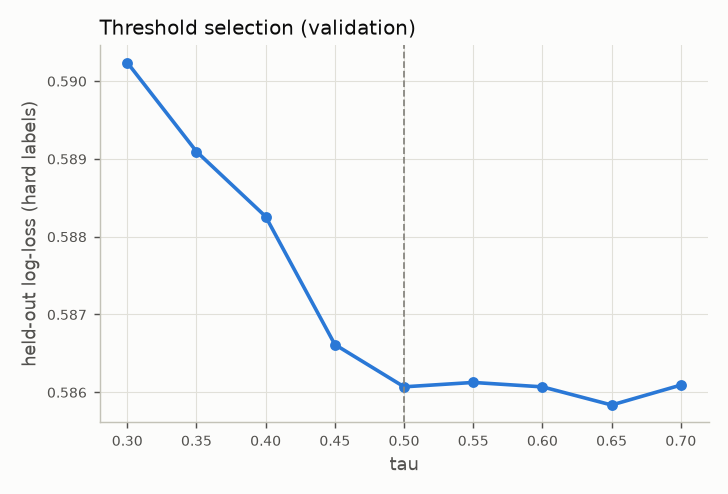

In [6]:
# 5. kebijakan diagnosis dari validation: threshold tau (one-SE rule), n_min dan delta (konsistensi split-half)
policy = p.step_policy()
display(pd.read_csv(p.out / "evaluation/threshold_selection_validation.csv"))
display(pd.read_csv(p.out / "evaluation/consistency_by_evidence_validation.csv"))
display(pd.read_csv(p.out / "evaluation/consistency_by_band_validation.csv"))
display(Image(str(p.out / "evaluation/figures/threshold_selection.png")))

                              model  roc_auc  log_loss    brier  accuracy       f1      ece
                      P-DINA (main) 0.768416  0.567872 0.194090  0.698639 0.704258 0.007726
P-DINA independent prior (ablation) 0.761305  0.574503 0.196907  0.692854 0.701219 0.006263
                Q-logistic baseline 0.774605  0.566964 0.193023  0.704103 0.725956 0.036301
             Concept-score baseline 0.718195  0.611279 0.212524  0.658251 0.681234 0.016475
                 Item-mean baseline 0.672187  0.643568 0.226298  0.626933 0.664655 0.005180


,model,n,base_rate,log_loss,brier,accuracy,precision,recall,f1,threshold,roc_auc,ece,roc_auc_ci95,log_loss_ci95
0,P-DINA (main),28003,0.536264,0.567872,0.194090,0.698639,0.743305,0.669108,0.704258,0.5,0.768416,0.007726,"[0.758671, 0.779355]","[0.556202, 0.576941]"
1,P-DINA independent prior (ablation),28003,0.536264,0.574503,0.196907,0.692854,0.732970,0.672105,0.701219,0.5,0.761305,0.006263,"[0.751378, 0.771508]","[0.563519, 0.584226]"
2,Q-logistic baseline,28003,0.536264,0.566964,0.193023,0.704103,0.721138,0.730838,0.725956,0.5,0.774605,0.036301,"[0.765733, 0.786213]","[0.554676, 0.576109]"
3,Concept-score baseline,28003,0.536264,0.611279,0.212524,0.658251,0.681506,0.680962,0.681234,0.5,0.718195,0.016475,"[0.706806, 0.732998]","[0.59848, 0.620593]"
4,Item-mean baseline,28003,0.536264,0.643568,0.226298,0.626933,0.641609,0.689419,0.664655,0.5,0.672187,0.005180,"[0.660843, 0.681705]","[0.637295, 0.651032]"


,comparison,auc_diff_ci95,logloss_diff_ci95,auc_diff_mean,logloss_diff_mean
0,P-DINA (main) - P-DINA independent prior (abla...,"[0.005048773910600488, 0.008965415331888894]","[-0.008474204137261535, -0.004742925268934785]",0.007093,-0.006576
1,P-DINA (main) - Q-logistic baseline,"[-0.01058228337180014, -0.002688515982716308]","[-0.0034705075603398525, 0.006709777670510656]",-0.006533,0.001340
2,P-DINA (main) - Concept-score baseline,"[0.040794633251352824, 0.05819933022783213]","[-0.049545818903603045, -0.035460028875398904]",0.049469,-0.042709
3,P-DINA (main) - Item-mean baseline,"[0.08438251556753092, 0.10989806584453185]","[-0.08661012338187336, -0.06698279156283915]",0.096955,-0.076226


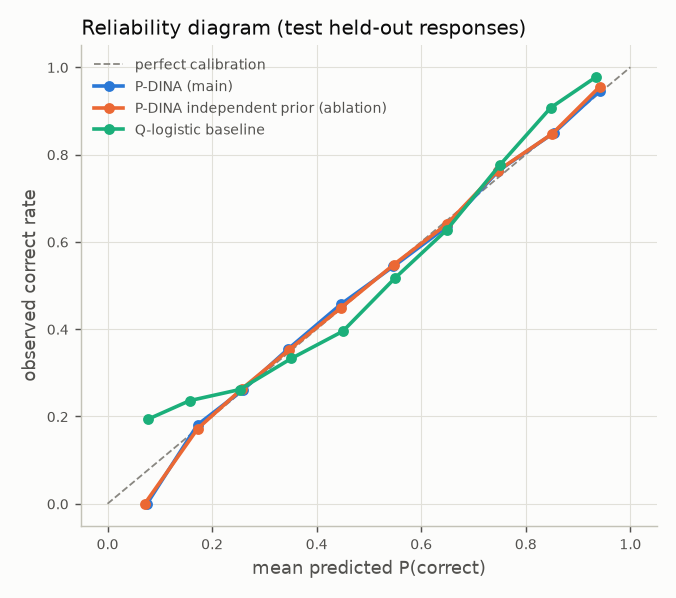

,concept_id,concept_name,n_items_in_bank,n_heldout_responses,n_items_evaluated,roc_auc,log_loss,brier,accuracy,base_rate,limited_items_flag,is_target
1,52,Factorising into a Single Bracket,8,375,8,0.783209,0.550564,0.185483,0.728000,0.498667,False,True
2,64,Linear Equations,7,308,7,0.752616,0.570730,0.194066,0.704545,0.487013,False,True
3,67,Substitution into Formula,22,1041,22,0.700525,0.600947,0.208499,0.682037,0.451489,False,True
4,70,Writing Expressions,25,1153,25,0.782740,0.552355,0.186381,0.727667,0.497832,False,True
14,166,Solving Linear Inequalities,8,287,8,0.719858,0.589903,0.202701,0.703833,0.473868,False,True
15,171,Linear Sequences (nth term),12,338,12,0.791487,0.545335,0.185115,0.713018,0.529586,False,True
47,251,Simplifying Expressions by Collecting Like Terms,19,1001,19,0.738115,0.594271,0.205204,0.681319,0.537463,False,True
48,258,Horizontal and Vertical Lines,8,213,8,0.689543,0.590135,0.201018,0.718310,0.370892,False,True
52,406,Naming Co-ordinates in 2D,24,685,24,0.750742,0.584347,0.200329,0.693431,0.513869,False,True
53,408,Midpoint Between Two Co-ordinates,9,272,9,0.691904,0.627880,0.218143,0.658088,0.437500,False,True


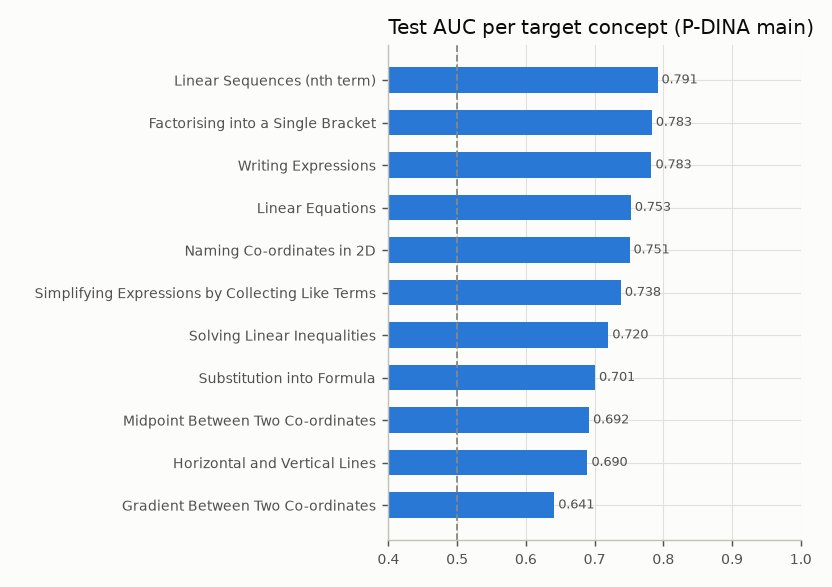

In [7]:
# 6. evaluasi test - SEKALI (pemanggilan kedua ditolak oleh pipeline)
tm = p.step_test_evaluation()
display(tm.drop(columns=["config"]))
display(pd.read_csv(p.out / "evaluation/test_model_differences.csv"))
display(Image(str(p.out / "evaluation/figures/calibration_test.png")))
pc = pd.read_csv(p.out / "evaluation/per_concept_test_main.csv")
display(pc[pc["is_target"]])
display(Image(str(p.out / "evaluation/figures/per_concept_auc_target.png")))

In [8]:
# 7. proksi kualitas diagnosis (tidak ada ground-truth mastery di EEDI)
p.step_diagnosis_quality()
display(pd.read_csv(p.out / "evaluation/consistency_by_concept_test.csv"))
display(pd.read_csv(p.out / "evaluation/simulation_mastery_recovery.csv"))

{
 "split_half_consistency_test": {
  "n_cells_with_n_min": 880,
  "consistency": 0.8761363636363636,
  "n_cells_outside_band": 880,
  "consistency_outside_band": 0.8761363636363636
 },
 "simulation_recovery": {
  "n_simulated_students": 1000,
  "tau": 0.5,
  "attribute_accuracy_with_evidence": 0.956549217885922,
  "attribute_accuracy_without_evidence": 0.8505673303361164,
  "label": "SIMULATION under the fitted model (not real ground truth)"
 },
 "item_parameter_recovery": {
  "n_items_with_30plus_responses": 900,
  "guess_corr": 0.9654269548286251,
  "slip_corr": 0.9823135701248491,
  "guess_mae": 0.022718750197318005,
  "slip_mae": 0.02033917214155539,
  "label": "SIMULATION: item-parameter recovery on train-sized data generated from the fitted model"
 },
 "caveat": "No ground-truth mastery exists in EEDI; these are reliability / simulation proxies, not diagnostic accuracy."
}


,concept_index,consistency,n_cells,concept_id,concept_name
0,3,0.896996,233,67,Substitution into Formula
1,4,0.863636,242,70,Writing Expressions
2,15,0.914286,35,171,Linear Sequences (nth term)
3,47,0.884956,226,251,Simplifying Expressions by Collecting Like Terms
4,52,0.840278,144,406,Naming Co-ordinates in 2D


,concept_index,n_students_with_evidence,true_mastery_rate,accuracy_with_evidence,auc_with_evidence,mean_evidence,accuracy_without_evidence,concept_id,concept_name
0,4,784,0.548,0.979592,0.997589,13.146684,0.907407,70,Writing Expressions
1,47,717,0.491,0.980474,0.998265,13.099024,0.862191,251,Simplifying Expressions by Collecting Like Terms
2,3,763,0.464,0.968545,0.996140,12.766710,0.831224,67,Substitution into Formula
3,1,771,0.439,0.942931,0.988887,4.226978,0.855895,52,Factorising into a Single Bracket
4,2,614,0.416,0.970684,0.995318,4.739414,0.836788,64,Linear Equations
5,14,607,0.468,0.929160,0.982602,4.444811,0.839695,166,Solving Linear Inequalities
6,15,551,0.530,0.943739,0.989748,5.103448,0.893096,171,Linear Sequences (nth term)
7,52,453,0.527,0.964680,0.996144,13.774834,0.893967,406,Naming Co-ordinates in 2D
8,53,421,0.348,0.947743,0.988646,5.669834,0.853195,408,Midpoint Between Two Co-ordinates
9,48,324,0.303,0.959877,0.993663,5.706790,0.841716,258,Horizontal and Vertical Lines


 concept_id                                     concept_name  n_items_total  n_items_reliable  n_items_eligible  n_items_eligible_single_concept  mean_discrimination_eligible difficulty_range_eligible  items_needed_for_two_forms  adequate_for_parallel_forms  adequate_for_single_form                          diagnosis_limitation
         70                              Writing Expressions             25                25                24                               24                      0.429600                 0.28-0.70                          10                         True                      True                                              
        251 Simplifying Expressions by Collecting Like Terms             19                19                19                               19                      0.448660                 0.25-0.65                          10                         True                      True                                              
         6

,concept_id,concept_name,n_items_total,n_items_reliable,n_items_eligible,n_items_eligible_single_concept,mean_discrimination_eligible,difficulty_range_eligible,items_needed_for_two_forms,adequate_for_parallel_forms,adequate_for_single_form,diagnosis_limitation
0,70,Writing Expressions,25,25,24,24,0.429600,0.28-0.70,10,True,True,NaN
1,251,Simplifying Expressions by Collecting Like Terms,19,19,19,19,0.448660,0.25-0.65,10,True,True,NaN
2,67,Substitution into Formula,22,22,21,21,0.445120,0.34-0.71,10,True,True,NaN
3,52,Factorising into a Single Bracket,8,8,8,8,0.563288,0.46-0.67,10,False,True,too few eligible items for two parallel forms
4,64,Linear Equations,7,7,7,7,0.555571,0.49-0.61,10,False,True,too few eligible items for two parallel forms
5,166,Solving Linear Inequalities,8,8,8,8,0.461397,0.38-0.69,10,False,True,too few eligible items for two parallel forms
6,171,Linear Sequences (nth term),12,12,11,11,0.455092,0.25-0.65,10,True,True,NaN
7,406,Naming Co-ordinates in 2D,24,24,22,22,0.335221,0.18-0.71,10,True,True,NaN
8,408,Midpoint Between Two Co-ordinates,9,9,9,9,0.485935,0.45-0.72,10,False,True,too few eligible items for two parallel forms
9,258,Horizontal and Vertical Lines,8,8,8,8,0.540218,0.50-0.70,10,False,True,too few eligible items for two parallel forms


,position,QuestionId,concept_names,model_difficulty,discrimination,guess,slip
0,1,137,Writing Expressions,0.367169,0.466253,0.421664,0.112083
1,2,82,Simplifying Expressions by Collecting Like Terms,0.360173,0.483102,0.450418,0.066480
2,3,90,Substitution into Formula,0.434817,0.591479,0.355455,0.053066
3,4,193,Factorising into a Single Bracket,0.461087,0.607319,0.333262,0.059420
4,5,859,Linear Equations,0.485962,0.600264,0.331915,0.067821
5,6,465,Solving Linear Inequalities,0.395008,0.552415,0.399521,0.048064
6,7,570,Linear Sequences (nth term),0.394812,0.582268,0.341335,0.076397
7,8,900,Naming Co-ordinates in 2D,0.274962,0.439224,0.527633,0.033143
8,9,489,Midpoint Between Two Co-ordinates,0.540204,0.526730,0.335864,0.137406
9,10,10,Horizontal and Vertical Lines,0.593512,0.597852,0.292034,0.110113


,concept_id,n_pairs,requested_pairs,shortfall,mean_difficulty_A,mean_difficulty_B,mean_discrimination_A,mean_discrimination_B,abs_difficulty_diff
0,70,5,5,False,0.435667,0.438599,0.512289,0.513493,0.002932
1,251,5,5,False,0.439246,0.435326,0.474709,0.511531,0.003921
2,67,5,5,False,0.462357,0.454465,0.556599,0.541772,0.007892
3,52,4,5,True,0.542508,0.541815,0.558893,0.567682,0.000692
4,64,3,5,True,0.519141,0.512670,0.585042,0.549936,0.006470
5,166,4,5,True,0.500956,0.485007,0.451024,0.471770,0.015948
6,171,5,5,False,0.427654,0.434226,0.515883,0.443991,0.006572
7,406,5,5,False,0.359353,0.322281,0.401435,0.386665,0.037072
8,408,4,5,True,0.559802,0.573375,0.501789,0.471065,0.013573
9,258,4,5,True,0.603323,0.614346,0.539235,0.541202,0.011023


,strategy,length,label_agreement,mean_abs_pi_diff,n_target_concepts_covered
0,adaptive_MI,5,0.788894,0.220126,4.310000
1,adaptive_MI,10,0.861950,0.144431,6.530000
2,adaptive_MI,15,0.891854,0.112815,7.503333
3,adaptive_MI,20,0.910676,0.094356,8.080000
4,random,5,0.770979,0.251745,3.653333
5,random,10,0.823765,0.187592,5.360000
6,random,15,0.850930,0.157976,6.273333
7,random,20,0.870664,0.129670,6.933333


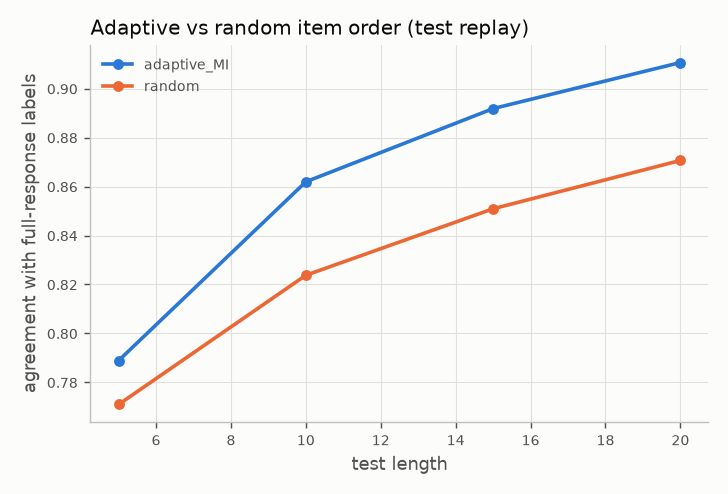

,topic_id,domain,level,topic_name,mapped_eedi_concept_ids,mapped_eedi_concept_names,mapping_type,n_items_total,n_items_eligible,adequate_for_pre_post_forms,notes
0,T01,algebra,SMA kelas X,Eksponen dan logaritma,NaN,NaN,unmapped,0,0,False,No EEDI Task 3/4 concept. EEDI 245 'Squares; C...
1,T02,algebra,SMA kelas X,Barisan dan deret (aritmetika dan geometri),171,Linear Sequences (nth term),partial,12,11,True,EEDI 171 covers nth term of linear (arithmetic...
2,T03,algebra,SMA kelas X,Sistem persamaan linear (SPLDV/SPLTV),64,Linear Equations,prerequisite_only,7,7,False,EEDI 64 covers single linear equations / equiv...
3,T04,algebra,SMA kelas X,Persamaan dan pertidaksamaan linear (termasuk ...,64;166,Linear Equations; Solving Linear Inequalities,partial,15,15,True,EEDI 166 sampled items compare expressions wit...
4,T05,algebra,SMA kelas X,Persamaan dan fungsi kuadrat,52,Factorising into a Single Bracket,prerequisite_only,8,8,False,EEDI 52 covers factorising into a single brack...
5,T06,algebra,SMA kelas X-XI,Fungsi (konsep; grafik; komposisi; invers),67;258;406;408,Substitution into Formula; Horizontal and Vert...,prerequisite_only,63,60,True,Substitution and coordinate-plane skills are p...
6,T07,algebra,SMA (prasyarat),Bentuk aljabar dan manipulasi ekspresi,70;251,Writing Expressions; Simplifying Expressions b...,prerequisite_only,44,43,True,Foundational SMP-level expression writing and ...
7,T08,algebra,SMA kelas XI,Polinomial,NaN,NaN,unmapped,0,0,False,No EEDI Task 3/4 concept.
8,T09,algebra,SMA kelas XI,Matriks,NaN,NaN,unmapped,0,0,False,No EEDI Task 3/4 concept.
9,T10,calculus,SMA kelas XI-XII,Limit fungsi,NaN,NaN,unmapped,0,0,False,No EEDI Task 3/4 concept.


,topic_id,domain,level,topic_name,notes
0,T01,algebra,SMA kelas X,Eksponen dan logaritma,No EEDI Task 3/4 concept. EEDI 245 'Squares; C...
1,T08,algebra,SMA kelas XI,Polinomial,No EEDI Task 3/4 concept.
2,T09,algebra,SMA kelas XI,Matriks,No EEDI Task 3/4 concept.
3,T10,calculus,SMA kelas XI-XII,Limit fungsi,No EEDI Task 3/4 concept.
4,T12,calculus,SMA kelas XII,Integral,No EEDI Task 3/4 concept.


In [9]:
# 8. CDA: kecukupan soal, fixed form, parallel forms, replay adaptif, cakupan kurikulum
p.step_assessment()
display(pd.read_csv(p.out / "assessment/concept_item_adequacy.csv"))
display(pd.read_csv(p.out / "assessment/fixed_form.csv")[["position", "QuestionId", "concept_names", "model_difficulty", "discrimination", "guess", "slip"]])
display(pd.read_csv(p.out / "assessment/parallel_forms_balance.csv"))
rs = p.out / "evaluation/adaptive_replay_summary.csv"
if rs.exists():
    display(pd.read_csv(rs)); display(Image(str(p.out / "evaluation/figures/adaptive_replay.png")))
display(pd.read_csv(p.out / "audit/coverage_report.csv"))
display(pd.read_csv(p.out / "audit/unmapped_target_topics.csv"))

 concept_id                                     concept_name  n_students  mean_mastery_prob  n_mastered  n_not_mastered  n_uncertain  n_insufficient  mean_evidence  n_diagnosable  gap_share_among_diagnosable  insufficient_share
        258                    Horizontal and Vertical Lines         492           0.175963          19              77            0             396       2.325203             96                     0.802083            0.804878
        408                Midpoint Between Two Co-ordinates         492           0.225831          28              76            0             388       2.741870            104                     0.730769            0.788618
         64                                 Linear Equations         492           0.287392          54             136            0             302       3.306911            190                     0.715789            0.613821
         67                        Substitution into Formula         492           0.328

,concept_id,concept_name,n_students,mean_mastery_prob,n_mastered,n_not_mastered,n_uncertain,n_insufficient,mean_evidence,n_diagnosable,gap_share_among_diagnosable,insufficient_share
0,258,Horizontal and Vertical Lines,492,0.175963,19,77,0,396,2.325203,96,0.802083,0.804878
1,408,Midpoint Between Two Co-ordinates,492,0.225831,28,76,0,388,2.741870,104,0.730769,0.788618
2,64,Linear Equations,492,0.287392,54,136,0,302,3.306911,190,0.715789,0.613821
3,67,Substitution into Formula,492,0.328641,88,210,0,194,11.026423,298,0.704698,0.394309
4,166,Solving Linear Inequalities,492,0.350296,38,88,0,366,3.146341,126,0.698413,0.743902
5,52,Factorising into a Single Bracket,492,0.326349,69,150,0,273,3.670732,219,0.684932,0.554878
6,251,Simplifying Expressions by Collecting Like Terms,492,0.373500,115,214,0,163,10.495935,329,0.650456,0.331301
7,70,Writing Expressions,492,0.434292,133,199,0,160,11.782520,332,0.599398,0.325203
8,171,Linear Sequences (nth term),492,0.430314,79,117,0,296,3.434959,196,0.596939,0.601626
9,406,Naming Co-ordinates in 2D,492,0.435915,104,127,0,261,7.239837,231,0.549784,0.530488


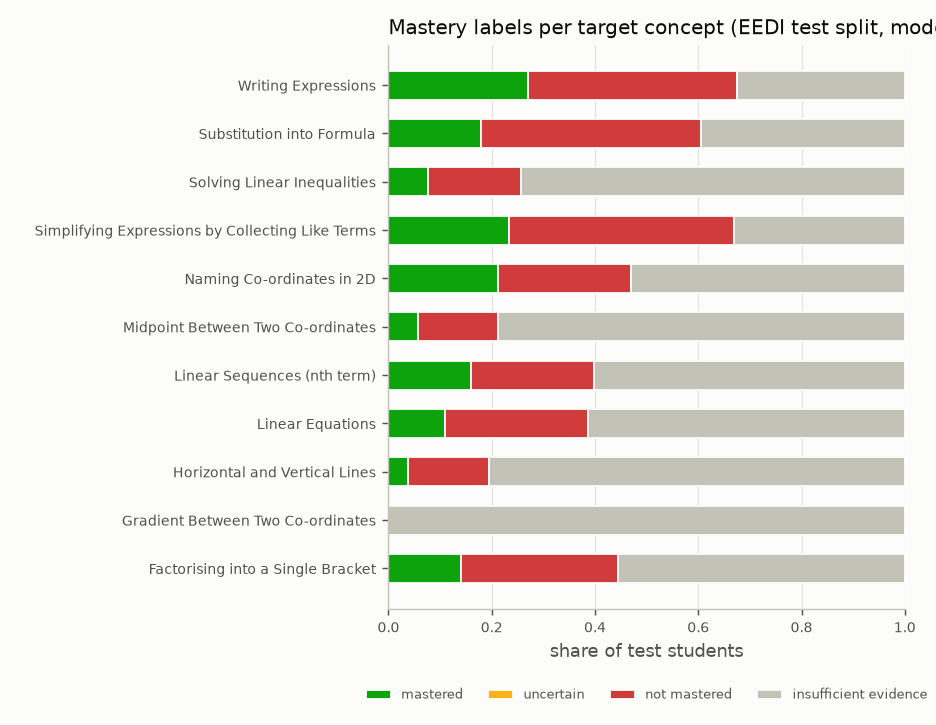

,student_id,concept_id,concept_name,is_target_concept,mastery_prob,mastery_label,n_evidence,n_correct,prior_mastery_prob,posterior_sd,entropy_bits,observed_score,tau,gap_status,need,certainty,priority_score,rank_within_student
0,6,171,Linear Sequences (nth term),True,0.000001,not_mastered,11,1,0.092921,0.001000,0.000021,0.090909,0.5,learning_gap,0.999998,0.999979,0.999977,1
1,6,251,Simplifying Expressions by Collecting Like Terms,True,0.000002,not_mastered,19,8,0.052066,0.001394,0.000040,0.421053,0.5,learning_gap,0.999996,0.999960,0.999956,2
2,6,67,Substitution into Formula,True,0.000065,not_mastered,22,8,0.034813,0.008077,0.001001,0.363636,0.5,learning_gap,0.999870,0.998999,0.998868,3
3,6,52,Factorising into a Single Bracket,True,0.000496,not_mastered,8,3,0.049628,0.022265,0.006160,0.375000,0.5,learning_gap,0.999008,0.993840,0.992854,4
4,6,64,Linear Equations,True,0.001162,not_mastered,7,3,0.025579,0.034068,0.013004,0.428571,0.5,learning_gap,0.997676,0.986996,0.984702,5
5,6,166,Solving Linear Inequalities,True,0.031832,not_mastered,8,4,0.072415,0.175553,0.203499,0.500000,0.5,learning_gap,0.936336,0.796501,0.745793,6
6,6,406,Naming Co-ordinates in 2D,True,0.041562,not_mastered,11,4,0.106785,0.199587,0.249410,0.363636,0.5,learning_gap,0.916876,0.750590,0.688198,7
7,6,70,Writing Expressions,True,0.335725,not_mastered,25,13,0.100835,0.472243,0.920669,0.520000,0.5,learning_gap,0.328551,0.079331,0.026064,8
8,6,258,Horizontal and Vertical Lines,True,0.000036,insufficient_evidence,4,0,0.013567,0.006030,0.000589,0.000000,0.5,needs_more_data,0.999927,0.999411,0.999339,9
9,6,408,Midpoint Between Two Co-ordinates,True,0.000449,insufficient_evidence,4,1,0.009902,0.021181,0.005639,0.250000,0.5,needs_more_data,0.999102,0.994361,0.993468,10


,0,1,2,3,4
student_id,6,6,6,6,6
concept_id,406,70,171,251,67
concept_name,Naming Co-ordinates in 2D,Writing Expressions,Linear Sequences (nth term),Simplifying Expressions by Collecting Like Terms,Substitution into Formula
gap_status,learning_gap,learning_gap,learning_gap,learning_gap,learning_gap
recommended_action,remediate,remediate,remediate,remediate,remediate
mastery_prob,0.041562,0.335725,0.000001,0.000002,0.000065
n_evidence,11,25,11,19,22
priority_score,0.688198,0.026064,0.999977,0.999956,0.998868
prerequisite_gaps,NaN,NaN,67.0,70.0,70.0
curriculum_order,8.0,1.0,7.0,2.0,3.0


In [10]:
# 9. profil mastery, learning gap, agregasi kelas, rekomendasi intervensi (siswa test, parameter beku)
p.step_diagnose_test()
display(pd.read_csv(p.out / "diagnosis/test_class_gap_summary.csv"))
display(Image(str(p.out / "evaluation/figures/test_mastery_labels_by_concept.png")))
display(pd.read_csv(p.out / "diagnosis/test_learning_gaps.csv").head(10))
display(pd.read_csv(p.out / "intervention/test_intervention_recommendations.csv").head(5).T)

In [11]:
# 10. demo pre/post dengan data SINTETIS (bukan hasil eksperimen, bukan siswa EEDI)
p.step_prepost_demo()
rep = json.loads((p.out / "prepost/SYNTHETIC_prepost_report.json").read_text())
print(rep["LABEL"]); print(rep["summary"]["interpretation_guard"])
display(pd.read_csv(p.out / "prepost/SYNTHETIC_concept_changes.csv"))
print("simulation check:", rep["simulation_check"])

SIMULATION - synthetic students generated from the fitted model; not EEDI students, not an experiment
No control/comparison group: results are OBSERVED CHANGES after the intervention period and must not be interpreted as evidence that the intervention caused them (maturation, retest and other effects are not ruled out).


,concept_id,concept_name,n_students_matched,n_both_diagnosable,n_pairs,mean_pre,mean_post,mean_change,mean_change_ci95,cohens_dz,wilcoxon_p,rank_biserial_r,paired_t_p,n_not_to_mastered,n_mastered_to_not,mcnemar_exact_p,n_increase,n_decrease,wilcoxon_p_holm,interpretation
0,70,Writing Expressions,40,21,21,0.517158,0.751184,0.234026,"[0.07797133756566323, 0.4237898771817665]",0.579424,0.000852,0.783550,0.015192,5,0,0.062500,18,3,0.004258,observed increase (statistically detectable)
1,251,Simplifying Expressions by Collecting Like Terms,40,25,25,0.507824,0.600106,0.092282,"[-0.07983115980082636, 0.26749724018279986]",0.202493,0.219986,0.286154,0.321414,5,3,0.726562,16,9,0.439973,no statistically detectable change
2,67,Substitution into Formula,40,29,29,0.358640,0.524004,0.165364,"[0.048682026609401824, 0.30248845602274455]",0.447068,0.056226,0.406897,0.022897,5,0,0.062500,19,10,0.168677,no statistically detectable change
3,52,Factorising into a Single Bracket,40,0,0,NaN,NaN,NaN,"[nan, nan]",NaN,NaN,NaN,NaN,0,0,NaN,0,0,NaN,insufficient paired data
4,64,Linear Equations,40,0,0,NaN,NaN,NaN,"[nan, nan]",NaN,NaN,NaN,NaN,0,0,NaN,0,0,NaN,insufficient paired data
5,166,Solving Linear Inequalities,40,0,0,NaN,NaN,NaN,"[nan, nan]",NaN,NaN,NaN,NaN,0,0,NaN,0,0,NaN,insufficient paired data
6,171,Linear Sequences (nth term),40,29,29,0.535208,0.748096,0.212888,"[0.07529244491476778, 0.36897784489870833]",0.512086,0.015745,0.508046,0.010135,7,0,0.015625,19,10,0.062978,no statistically detectable change
7,406,Naming Co-ordinates in 2D,40,22,22,0.687625,0.754613,0.066988,"[-0.12817014590208323, 0.27894743724438303]",0.133651,0.678863,-0.106719,0.537495,4,2,0.687500,8,14,0.678863,no statistically detectable change
8,408,Midpoint Between Two Co-ordinates,40,0,0,NaN,NaN,NaN,"[nan, nan]",NaN,NaN,NaN,NaN,0,0,NaN,0,0,NaN,insufficient paired data
9,258,Horizontal and Vertical Lines,40,0,0,NaN,NaN,NaN,"[nan, nan]",NaN,NaN,NaN,NaN,0,0,NaN,0,0,NaN,insufficient paired data


simulation check: {'corr_estimated_change_vs_true_change': 0.7437636015602151, 'true_gain_rate_target': 0.2431818181818182}


In [12]:
# 11. simpan checkpoint + ringkasan
p.step_save()
for f in sorted((p.out / "model").iterdir()):
    print(f"{f.name:40s} {f.stat().st_size/1024:8.1f} KB")

checkpoint written to D:\finalIL\artifacts\model
concept_metadata.csv                          9.5 KB
diagnosis_policy.json                         0.8 KB
experiment_config_used.json                   3.9 KB
intervention_map_resolved.csv                 7.4 KB
item_bank.csv                               212.4 KB
item_parameters.csv                         197.1 KB
model_card.json                              16.4 KB
pdina_config.json                             0.6 KB
pdina_params.npz                            448.1 KB
q_matrix.csv                                110.3 KB
target_concept_map.csv                       13.0 KB


## Inference API (tanpa retraining)

`predict_mastery()`, `select_assessment()`, `detect_learning_gaps()`, `recommend_intervention()`, `compare_pre_post()` memuat checkpoint
dan hanya menjalankan E-step dengan parameter soal yang dibekukan.

In [13]:
from cdacdm.api import load_model, predict_mastery, select_assessment, detect_learning_gaps, recommend_intervention, compare_pre_post
svc = load_model(p.out)
# siswa baru dengan jawaban parsial: 3 soal dijawab, 1 dikosongkan (tidak dianggap salah)
form = svc.forms["fixed"]
new = {"SISWA-BARU-01": {int(q): r for q, r in zip(form["QuestionId"][:4], [1, 0, 1, None])}}
prof = predict_mastery(new, service=svc, only_target=True)
display(prof[["student_id", "concept_name", "mastery_prob", "mastery_label", "n_evidence", "posterior_sd"]])
gaps = detect_learning_gaps(prof, service=svc)
display(gaps[["concept_name", "gap_status", "mastery_prob", "n_evidence", "priority_score"]])
display(recommend_intervention(gaps, service=svc)[["concept_name", "recommended_action", "is_placeholder", "rule_trace"]])

,student_id,concept_name,mastery_prob,mastery_label,n_evidence,posterior_sd
0,SISWA-BARU-01,Factorising into a Single Bracket,0.359089,insufficient_evidence,0,0.479733
1,SISWA-BARU-01,Linear Equations,0.272775,insufficient_evidence,0,0.445386
2,SISWA-BARU-01,Substitution into Formula,0.624252,insufficient_evidence,1,0.484315
3,SISWA-BARU-01,Writing Expressions,0.803266,insufficient_evidence,1,0.397530
4,SISWA-BARU-01,Solving Linear Inequalities,0.433048,insufficient_evidence,0,0.495497
5,SISWA-BARU-01,Linear Sequences (nth term),0.639149,insufficient_evidence,0,0.480247
6,SISWA-BARU-01,Simplifying Expressions by Collecting Like Terms,0.103040,insufficient_evidence,1,0.304012
7,SISWA-BARU-01,Horizontal and Vertical Lines,0.111470,insufficient_evidence,0,0.314713
8,SISWA-BARU-01,Naming Co-ordinates in 2D,0.616292,insufficient_evidence,0,0.486288
9,SISWA-BARU-01,Midpoint Between Two Co-ordinates,0.138793,insufficient_evidence,0,0.345730


,concept_name,gap_status,mastery_prob,n_evidence,priority_score
0,Simplifying Expressions by Collecting Like Terms,needs_more_data,0.103040,1,0.413982
1,Horizontal and Vertical Lines,needs_more_data,0.111470,0,0.385163
2,Midpoint Between Two Co-ordinates,needs_more_data,0.138793,0,0.302642
3,Linear Equations,needs_more_data,0.272775,0,0.070250
4,Factorising into a Single Bracket,needs_more_data,0.359089,0,0.016367
5,Solving Linear Inequalities,needs_more_data,0.433048,0,0.001737
6,Gradient Between Two Co-ordinates,needs_more_data,0.465795,0,0.000231


,concept_name,recommended_action,is_placeholder,rule_trace
0,Simplifying Expressions by Collecting Like Terms,collect_more_evidence,True,R1: insufficient evidence -> administer diagno...
1,Horizontal and Vertical Lines,collect_more_evidence,True,R1: insufficient evidence -> administer diagno...
2,Midpoint Between Two Co-ordinates,collect_more_evidence,True,R1: insufficient evidence -> administer diagno...
3,Linear Equations,collect_more_evidence,True,R1: insufficient evidence -> administer diagno...
4,Factorising into a Single Bracket,collect_more_evidence,True,R1: insufficient evidence -> administer diagno...
5,Solving Linear Inequalities,collect_more_evidence,True,R1: insufficient evidence -> administer diagno...
6,Gradient Between Two Co-ordinates,collect_more_evidence,True,R1: insufficient evidence -> administer diagno...


In [14]:
# sesi adaptif: jawaban disimulasikan dari respons nyata seorang siswa test (hanya soal yang ia kerjakan)
te = p.bundle.splits["test"]
i = int(np.argmax(te.M[:, svc.items["eligible_target_item"].to_numpy()].sum(1)))
answers = {int(q): te.X[i, j] for j, q in enumerate(svc.question_ids) if te.M[i, j]}
sess = select_assessment("adaptive", service=svc, max_length=12)
sess.pool &= set(answers)
sess.run_with_oracle(lambda q: answers[q])
print("soal yang dipilih:", sess.administered)
display(pd.DataFrame({"concept": [svc.concept_names[list(svc.concept_ids).index(c)] for c in svc.policy.target_concept_ids],
                      "pi": [sess.post.pi[0, list(svc.concept_ids).index(c)] for c in svc.policy.target_concept_ids],
                      "n_evidence": [sess.post.n_evidence[0, list(svc.concept_ids).index(c)] for c in svc.policy.target_concept_ids]}))

soal yang dipilih: [398, 193, 354, 433, 498, 90, 859, 934, 782, 551, 885, 465]


,concept,pi,n_evidence
0,Writing Expressions,0.799988,1
1,Simplifying Expressions by Collecting Like Terms,0.067200,1
2,Substitution into Formula,0.031923,1
3,Factorising into a Single Bracket,0.773150,2
4,Linear Equations,0.069018,2
5,Solving Linear Inequalities,0.041132,1
6,Linear Sequences (nth term),0.757023,1
7,Naming Co-ordinates in 2D,0.517553,0
8,Midpoint Between Two Co-ordinates,0.020213,1
9,Horizontal and Vertical Lines,0.010515,1


## Yang membutuhkan data kelas nyata

`compare_pre_post(pre, post, service=svc)` siap dipakai, tetapi hasil penelitian **baru dapat dihasilkan setelah** tersedia:

1. CSV pre-test dan post-test format panjang `student_id,QuestionId,response` (1/0/kosong) atau `answer_option` (1-4), dengan
   `student_id` yang sama di kedua tes; opsional kolom `group` (treatment/control).
2. Soal yang dipakai harus ada di item bank model (gunakan `assessment/parallel_form_A.csv` & `parallel_form_B.csv`, atau form sama).
   Jika kelas penelitian memakai soal SMA baru (aljabar lanjut / kalkulus), soal tersebut **harus dipetakan ke Q-matrix dan
   parameternya dikalibrasi** dulu — EEDI tidak memiliki konsep kalkulus (lihat `audit/unmapped_target_topics.csv`).
3. Tanpa kelompok kontrol, hasil dilaporkan sebagai *perubahan yang teramati setelah intervensi*, bukan efek kausal.